In [0]:
CATALOG = "balaji_azure"
SCHEMA = "default"
BASE_PATH = "/Workspace/Users/azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com/Drafts"
PREFIX = f"{CATALOG}.{SCHEMA}"

from pyspark.sql import functions as F
from delta.tables import DeltaTable

entries = spark.table(f"{PREFIX}.tp_entries_raw")
attractions = spark.table(f"{PREFIX}.tp_attractions")
maintenance = spark.table(f"{PREFIX}.tp_maintenance")
changes = spark.table(f"{PREFIX}.tp_entry_changes")

## A. Data ingestion and exploration

In [0]:
table_names = ["tp_entries_raw", "tp_attractions", "tp_maintenance", "tp_entry_changes"]
for name in table_names:
    df = spark.table(f"{PREFIX}.{name}")
    print(name, df.count())
    display(df)

tp_entries_raw 121


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


tp_attractions 10


attraction_id,attraction_name,capacity_per_hour,category,features,is_active,location,min_height_cm,opened_year
A01,Sky Spinner,140,Thrill,"List(Outdoor, High Speed)",true,"List(N1, North)",120,2018
A02,Coral Carousel,200,Family,"List(Indoor, Family Friendly)",true,"List(E2, East)",0,2015
A03,Jungle Rapids,110,Water,"List(Water Ride, Outdoor)",true,"List(S1, South)",110,2020
A04,Moonlight Train,180,Family,"List(Scenic, Family Friendly)",true,"List(W3, West)",0,2012
A05,Meteor Drop,100,Thrill,"List(High Speed, Outdoor)",true,"List(N2, North)",135,2022
A06,Pirate Voyage,130,Water,"List(Water Ride, Themed)",true,"List(E1, East)",100,2019
A07,Crystal Maze,160,Adventure,"List(Indoor, Puzzle)",true,"List(S3, South)",90,2021
A08,Forest Flyers,120,Adventure,"List(Outdoor, Interactive)",true,"List(W1, West)",115,2023
A09,Galaxy Theater,260,Show,"List(Indoor, Live Show)",true,"List(N3, North)",0,2017
A10,Mini Explorers,190,Family,"List(Kids, Indoor)",true,"List(E3, East)",0,2016


tp_maintenance 28


maintenance_id,attraction_id,maintenance_date,issue_type,downtime_minutes,maintenance_status
M001,A05,2026-10-15,Cleaning,90,Scheduled
M002,A08,2026-10-05,Mechanical,60,Completed
M003,A02,2026-10-12,Mechanical,0,Scheduled
M004,A09,2026-10-18,Electrical,0,Open
M005,A05,2026-10-12,Electrical,0,Scheduled
M006,A04,2026-10-07,Water System,45,Completed
M007,A10,2026-10-20,Mechanical,120,Completed
M008,A04,2026-10-04,Water System,90,Open
M009,A08,2026-10-19,Safety Check,30,Scheduled
M010,A02,2026-10-15,Safety Check,0,Open


tp_entry_changes 10


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
entries.printSchema()
for field in entries.schema.fields:
    print(field.name, field.dataType)

root
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- attraction_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)

entry_id IntegerType()
visitor_id StringType()
attraction_id StringType()
visit_date StringType()
entry_time StringType()
wait_minutes IntegerType()
ride_minutes IntegerType()
ticket_type StringType()
ticket_price DoubleType()
status StringType()
booking_channel StringType()


In [0]:
display(entries.select("entry_id", "attraction_id", "visit_date", "ticket_type", "ticket_price").limit(20))

entry_id,attraction_id,visit_date,ticket_type,ticket_price
1001,A08,2026-10-06,Standard,350.0
1002,A01,2026-10-10,Standard,350.0
1003,A04,2026-10-11,Standard,350.0
1004,A05,2026-10-15,Express,650.0
1005,A07,2026-10-07,Standard,350.0
1006,A08,2026-10-09,VIP,900.0
1007,A08,2026-10-14,Standard,350.0
1008,A06,2026-10-01,Express,650.0
1009,A02,2026-10-16,Standard,350.0
1010,A02,2026-10-09,Express,600.0


In [0]:
display(entries.filter((F.col("status") == "Completed") & (F.col("ticket_price") > 500)))

In [0]:
display(entries.select("ticket_type").distinct())
display(entries.select("booking_channel").distinct())
display(entries.filter(F.col("ticket_type").isin("Standard", "Express")))
display(entries.filter(F.col("booking_channel").isin("App", "Web")))

ticket_type
Standard
Express
VIP


booking_channel
App
Web
Kiosk
Partner
null


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk
1011,V536,A02,2026-10-06,16:40:00,25,8,Standard,350.0,Cancelled,App


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1011,V536,A02,2026-10-06,16:40:00,25,8,Standard,350.0,Cancelled,App
1012,V543,A07,2026-10-13,12:20:00,25,20,Express,600.0,Cancelled,Web
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1018,V535,A10,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App


In [0]:
entries_by_date = (entries.withColumn("visit_date", F.to_date("visit_date"))
    .groupBy("visit_date").agg(F.count("*").alias("entry_count")).orderBy("visit_date"))
display(entries_by_date)

visit_date,entry_count
2026-10-01,11
2026-10-02,4
2026-10-03,13
2026-10-04,7
2026-10-05,4
2026-10-06,6
2026-10-07,8
2026-10-08,7
2026-10-09,10
2026-10-10,7


## B. Cleaning and transformation

In [0]:
missing_values = entries.filter(F.col("ticket_price").isNull() | F.col("booking_channel").isNull())
display(missing_values)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1016,V563,A10,2026-10-08,15:10:00,30,10,Standard,null,Completed,Kiosk
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,400.0,Completed,null
1071,V553,A07,2026-10-03,11:10:00,5,20,Standard,null,Completed,Partner
1087,V537,A01,2026-10-11,10:00:00,75,4,Standard,350.0,Completed,null


In [0]:
entries_filled = entries.withColumn("booking_channel", F.coalesce("booking_channel", F.lit("Unknown")))
display(entries_filled)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,Unknown
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk


In [0]:
invalid_records = entries.filter((F.col("wait_minutes") < 0) | (F.col("ride_minutes") == 0) | (F.col("ticket_price") <= 0))
display(invalid_records)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1021,V527,A03,2026-10-02,13:00:00,-8,8,Express,650.0,Completed,Web
1036,V527,A06,2026-10-04,14:40:00,40,0,Standard,400.0,Completed,Kiosk
1058,V516,A02,2026-10-08,19:10:00,30,4,Standard,0.0,Completed,App
1073,V501,A03,2026-10-07,18:50:00,-3,6,Express,650.0,Completed,App


In [0]:
duplicate_ids = (entries.groupBy("entry_id").agg(F.count("*").alias("record_count")).filter(F.col("record_count") > 1))
display(duplicate_ids)
entries_deduplicated = entries.dropDuplicates(["entry_id"])
print("Before:", entries.count(), "After:", entries_deduplicated.count())

entry_id,record_count
1032,2


Before: 121 After: 120


In [0]:
unknown_attractions = entries.join(attractions.select("attraction_id"), "attraction_id", "left_anti")
display(unknown_attractions)

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A99,1092,V566,2026-10-03,15:40:00,75,20,Standard,400.0,Completed,Kiosk


In [0]:
wait_category_df = (entries.filter(F.col("wait_minutes") >= 0)
    .withColumn("wait_category", F.when(F.col("wait_minutes").between(0, 20), "Short")
        .when(F.col("wait_minutes").between(21, 45), "Medium").otherwise("Long")))
display(wait_category_df)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,wait_category
1001,V515,A08,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App,Short
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App,Long
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web,Medium
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web,Short
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk,Short
1006,V549,A08,2026-10-09,10:30:00,10,8,VIP,900.0,Completed,Web,Short
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web,Short
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk,Medium
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null,Short
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,600.0,Cancelled,Kiosk,Short


In [0]:
entries_attractions = (entries.join(attractions, "attraction_id", "inner")
    .select(entries.entry_id, entries.visitor_id, entries.attraction_id,
            attractions.attraction_name, attractions.category,
            attractions["location.zone"].alias("zone"), attractions.features))
display(entries_attractions)

entry_id,visitor_id,attraction_id,attraction_name,category,zone,features
1001,V515,A08,Forest Flyers,Adventure,West,"List(Outdoor, Interactive)"
1002,V535,A01,Sky Spinner,Thrill,North,"List(Outdoor, High Speed)"
1003,V547,A04,Moonlight Train,Family,West,"List(Scenic, Family Friendly)"
1004,V517,A05,Meteor Drop,Thrill,North,"List(High Speed, Outdoor)"
1005,V537,A07,Crystal Maze,Adventure,South,"List(Indoor, Puzzle)"
1006,V549,A08,Forest Flyers,Adventure,West,"List(Outdoor, Interactive)"
1007,V529,A08,Forest Flyers,Adventure,West,"List(Outdoor, Interactive)"
1008,V521,A06,Pirate Voyage,Water,East,"List(Water Ride, Themed)"
1009,V510,A02,Coral Carousel,Family,East,"List(Indoor, Family Friendly)"
1010,V560,A02,Coral Carousel,Family,East,"List(Indoor, Family Friendly)"


## C. Joins and aggregations

In [0]:
completed_range = entries.filter((F.col("status") == "Completed") &
    F.col("ticket_type").isin("Standard", "Express") & F.col("ticket_price").between(300, 700))
display(completed_range)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1002,V535,A01,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
1004,V517,A05,2026-10-15,17:50:00,20,6,Express,650.0,Completed,Web
1005,V537,A07,2026-10-07,16:50:00,5,6,Standard,350.0,Completed,Kiosk
1007,V529,A08,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web
1008,V521,A06,2026-10-01,13:40:00,40,6,Express,650.0,Completed,Kiosk
1009,V510,A02,2026-10-16,16:00:00,10,8,Standard,350.0,Completed,null
1013,V506,A09,2026-10-11,10:20:00,15,20,Standard,350.0,Completed,Web
1015,V529,A05,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
1017,V501,A10,2026-10-06,17:50:00,40,8,Standard,350.0,Completed,Partner


In [0]:
valid_completed = (entries_deduplicated.filter((F.col("status") == "Completed") &
    F.col("ticket_price").isNotNull() & (F.col("ticket_price") > 0)))
revenue_by_attraction = (valid_completed.groupBy("attraction_id")
    .agg(F.sum("ticket_price").alias("total_ticket_revenue"), F.count("*").alias("completed_entry_count"))
    .join(attractions.select("attraction_id", "attraction_name"), "attraction_id", "left"))
display(revenue_by_attraction)

attraction_id,total_ticket_revenue,completed_entry_count,attraction_name
A04,4850.0,11,Moonlight Train
A03,4500.0,8,Jungle Rapids
A10,6050.0,13,Mini Explorers
A99,400.0,1,null
A05,5850.0,10,Meteor Drop
A09,3200.0,7,Galaxy Theater
A08,3600.0,8,Forest Flyers
A07,4750.0,9,Crystal Maze
A01,4200.0,9,Sky Spinner
A06,4600.0,9,Pirate Voyage


In [0]:
average_wait = (entries.filter(F.col("wait_minutes") >= 0)
    .join(attractions.select("attraction_id", "category"), "attraction_id")
    .groupBy("category").agg(F.avg("wait_minutes").alias("average_wait_minutes")))
display(average_wait)

category,average_wait_minutes
Family,31.463414634146343
Thrill,30.5
Show,35.90909090909091
Adventure,33.958333333333336
Water,25.227272727272727


In [0]:
maintenance_summary = (maintenance.filter(F.col("maintenance_status") == "Completed")
    .join(attractions.select("attraction_id", "attraction_name"), "attraction_id")
    .groupBy("attraction_id", "attraction_name")
    .agg(F.sum("downtime_minutes").alias("total_downtime_minutes")))
display(maintenance_summary)

attraction_id,attraction_name,total_downtime_minutes
A04,Moonlight Train,75
A09,Galaxy Theater,0
A03,Jungle Rapids,30
A08,Forest Flyers,60
A06,Pirate Voyage,135
A07,Crystal Maze,120
A01,Sky Spinner,120
A02,Coral Carousel,240
A10,Mini Explorers,120


In [0]:
revenue_by_zone = (valid_completed.join(attractions.select("attraction_id", F.col("location.zone").alias("zone")), "attraction_id")
    .groupBy("zone").agg(F.sum("ticket_price").alias("total_revenue"), F.count("*").alias("completed_entry_count")))
display(revenue_by_zone)

zone,total_revenue,completed_entry_count
West,8450.0,19
South,9250.0,17
East,12650.0,27
North,13250.0,26


## D. Delta tables and CRUD

In [0]:
entries_clean = (entries.dropDuplicates(["entry_id"])
    .filter((F.col("wait_minutes") >= 0) & (F.col("ride_minutes") > 0) &
            F.col("ticket_price").isNotNull() & (F.col("ticket_price") > 0))
    .join(attractions.select("attraction_id"), "attraction_id", "inner")
    .withColumn("booking_channel", F.coalesce("booking_channel", F.lit("Unknown"))))
entries_clean.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{PREFIX}.tp_entries_work")
work = spark.table(f"{PREFIX}.tp_entries_work")
print("Working rows:", work.count())
display(work)

Working rows: 113


attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A04,1003,V547,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
A10,1030,V557,2026-10-10,18:30:00,5,20,Standard,350.0,Completed,Kiosk
A04,1044,V548,2026-10-10,11:20:00,65,20,Express,600.0,Pending,App
A09,1088,V542,2026-10-11,10:50:00,20,15,VIP,900.0,Cancelled,Web
A03,1108,V543,2026-10-16,11:00:00,10,4,Express,650.0,Pending,Partner
A05,1015,V529,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
A09,1022,V543,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
A09,1025,V513,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
A08,1060,V542,2026-10-05,11:20:00,15,12,Standard,350.0,Completed,App
A04,1084,V525,2026-10-09,11:20:00,10,10,Express,600.0,Cancelled,App


In [0]:
attractions.write.format("delta").mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{PREFIX}.tp_attractions_copy")
display(spark.table(f"{PREFIX}.tp_attractions_copy"))

attraction_id,attraction_name,capacity_per_hour,category,features,is_active,location,min_height_cm,opened_year
A01,Sky Spinner,140,Thrill,"List(Outdoor, High Speed)",true,"List(N1, North)",120,2018
A02,Coral Carousel,200,Family,"List(Indoor, Family Friendly)",true,"List(E2, East)",0,2015
A03,Jungle Rapids,110,Water,"List(Water Ride, Outdoor)",true,"List(S1, South)",110,2020
A04,Moonlight Train,180,Family,"List(Scenic, Family Friendly)",true,"List(W3, West)",0,2012
A05,Meteor Drop,100,Thrill,"List(High Speed, Outdoor)",true,"List(N2, North)",135,2022
A06,Pirate Voyage,130,Water,"List(Water Ride, Themed)",true,"List(E1, East)",100,2019
A07,Crystal Maze,160,Adventure,"List(Indoor, Puzzle)",true,"List(S3, South)",90,2021
A08,Forest Flyers,120,Adventure,"List(Outdoor, Interactive)",true,"List(W1, West)",115,2023
A09,Galaxy Theater,260,Show,"List(Indoor, Live Show)",true,"List(N3, North)",0,2017
A10,Mini Explorers,190,Family,"List(Kids, Indoor)",true,"List(E3, East)",0,2016


In [0]:
new_entries = [(900001, "V9001", "A01", "2026-11-11", "10:30:00", 15, 20, "Standard", 350.0, "Completed", "App"),
               (900002, "V9002", "A02", "2026-11-11", "11:00:00", 25, 15, "Express", 600.0, "Pending", "Web")]
columns = ["entry_id", "visitor_id", "attraction_id", "visit_date", "entry_time", "wait_minutes", "ride_minutes", "ticket_type", "ticket_price", "status", "booking_channel"]
spark.createDataFrame(new_entries, columns).write.format("delta").mode("append").saveAsTable(f"{PREFIX}.tp_entries_work")

In [0]:
work_table = DeltaTable.forName(spark, f"{PREFIX}.tp_entries_work")
work_table.update(condition="entry_id = 900001", set={"status": F.lit("Completed"), "ticket_price": F.lit(450.0)})
display(spark.table(f"{PREFIX}.tp_entries_work").filter("entry_id = 900001"))

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A01,900001,V9001,2026-11-11,10:30:00,15,20,Standard,450.0,Completed,App


In [0]:
cancelled = spark.table(f"{PREFIX}.tp_entries_work").filter(F.col("status") == "Cancelled").select("entry_id").limit(1).collect()
if cancelled:
    work_table.delete(F.col("entry_id") == F.lit(cancelled[0]["entry_id"]))
    print("Deleted entry:", cancelled[0]["entry_id"])
display(spark.table(f"{PREFIX}.tp_entries_work").filter("status = 'Cancelled'"))

Deleted entry: 1088


attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A04,1084,V525,2026-10-09,11:20:00,10,10,Express,600.0,Cancelled,App
A06,1100,V524,2026-10-07,13:00:00,15,12,Standard,400.0,Cancelled,Partner
A10,1043,V542,2026-10-03,12:10:00,40,8,Express,600.0,Cancelled,Kiosk
A02,1011,V536,2026-10-06,16:40:00,25,8,Standard,350.0,Cancelled,App
A08,1001,V515,2026-10-06,17:20:00,15,20,Standard,350.0,Cancelled,App
A03,1035,V511,2026-10-10,19:50:00,65,15,Express,650.0,Cancelled,Partner
A07,1038,V554,2026-10-03,19:00:00,20,20,Standard,350.0,Cancelled,Partner
A09,1052,V501,2026-10-09,15:00:00,30,6,Standard,350.0,Cancelled,Partner
A07,1012,V543,2026-10-13,12:20:00,25,20,Express,600.0,Cancelled,Web
A03,1101,V537,2026-10-05,16:40:00,25,12,Standard,400.0,Cancelled,Partner


In [0]:
spark.sql(f"DESCRIBE EXTENDED {PREFIX}.tp_entries_work").show(100, truncate=False)

+----------------------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|col_name                    |data_type                                                                                                                                          

## E. MERGE / UPSERT and SCD

In [0]:
work_df = spark.table(f"{PREFIX}.tp_entries_work")
existing_changes = changes.join(work_df.select("entry_id"), "entry_id", "inner")
new_changes = changes.join(work_df.select("entry_id"), "entry_id", "left_anti")
display(existing_changes)
display(new_changes)

entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,V547,A04,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,V560,A02,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,V514,A03,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,V531,A10,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,V563,A07,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1121,V700,A01,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,V701,A02,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,V702,A03,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,V703,A04,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,V704,A05,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
source_df = changes.withColumn("booking_channel", F.coalesce("booking_channel", F.lit("Unknown")))
target = DeltaTable.forName(spark, f"{PREFIX}.tp_entries_work")
(target.alias("target").merge(source_df.alias("source"), "target.entry_id = source.entry_id")
 .whenMatchedUpdateAll().whenNotMatchedInsertAll().execute())
display(spark.table(f"{PREFIX}.tp_entries_work"))

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A10,1030,V557,2026-10-10,18:30:00,5,20,Standard,350.0,Completed,Kiosk
A04,1044,V548,2026-10-10,11:20:00,65,20,Express,600.0,Pending,App
A03,1108,V543,2026-10-16,11:00:00,10,4,Express,650.0,Pending,Partner
A05,1015,V529,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
A09,1022,V543,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
A09,1025,V513,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
A08,1060,V542,2026-10-05,11:20:00,15,12,Standard,350.0,Completed,App
A04,1084,V525,2026-10-09,11:20:00,10,10,Express,600.0,Cancelled,App
A05,1089,V501,2026-10-12,16:10:00,5,6,Express,650.0,Completed,Partner
A07,1094,V511,2026-10-16,15:10:00,10,20,Express,600.0,Completed,App


In [0]:
display(spark.table(f"{PREFIX}.tp_entries_work").join(changes.select("entry_id"), "entry_id", "inner").orderBy("entry_id"))

entry_id,attraction_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1003,A04,V547,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App
1010,A02,V560,2026-10-09,11:10:00,15,12,Express,675.0,Completed,App
1040,A03,V514,2026-10-01,19:10:00,5,15,Standard,500.0,Completed,App
1068,A10,V531,2026-10-15,16:20:00,30,4,Express,725.0,Completed,App
1095,A07,V563,2026-10-09,11:20:00,75,4,Standard,500.0,Completed,App
1121,A01,V700,2026-10-20,11:00:00,15,8,Standard,350.0,Completed,Web
1122,A02,V701,2026-10-20,12:00:00,20,10,Express,600.0,Completed,Web
1123,A03,V702,2026-10-20,13:00:00,25,12,Standard,350.0,Completed,Web
1124,A04,V703,2026-10-20,14:00:00,30,14,Express,600.0,Completed,Web
1125,A05,V704,2026-10-20,15:00:00,35,16,Standard,350.0,Completed,Web


In [0]:
spark.table(f"{PREFIX}.tp_entries_work").write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.tp_entries_merge_pyspark")
merge_copy = DeltaTable.forName(spark, f"{PREFIX}.tp_entries_merge_pyspark")
(merge_copy.alias("target").merge(source_df.alias("source"), "target.entry_id = source.entry_id")
 .whenMatchedUpdateAll().whenNotMatchedInsertAll().execute())
display(spark.table(f"{PREFIX}.tp_entries_merge_pyspark"))

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A10,1030,V557,2026-10-10,18:30:00,5,20,Standard,350.0,Completed,Kiosk
A04,1044,V548,2026-10-10,11:20:00,65,20,Express,600.0,Pending,App
A03,1108,V543,2026-10-16,11:00:00,10,4,Express,650.0,Pending,Partner
A05,1015,V529,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
A09,1022,V543,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
A09,1025,V513,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
A08,1060,V542,2026-10-05,11:20:00,15,12,Standard,350.0,Completed,App
A04,1084,V525,2026-10-09,11:20:00,10,10,Express,600.0,Cancelled,App
A05,1089,V501,2026-10-12,16:10:00,5,6,Express,650.0,Completed,Partner
A07,1094,V511,2026-10-16,15:10:00,10,20,Express,600.0,Completed,App


In [0]:
capacity_history = attractions.select("attraction_id", "attraction_name", "capacity_per_hour",
    F.make_date(F.col("opened_year"), F.lit(1), F.lit(1)).alias("valid_from"),
    F.lit(None).cast("date").alias("valid_to"), F.lit(True).alias("is_current"))
capacity_history.write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.attraction_capacity_history")
display(spark.table(f"{PREFIX}.attraction_capacity_history"))

attraction_id,attraction_name,capacity_per_hour,valid_from,valid_to,is_current
A01,Sky Spinner,140,2018-01-01,null,true
A02,Coral Carousel,200,2015-01-01,null,true
A03,Jungle Rapids,110,2020-01-01,null,true
A04,Moonlight Train,180,2012-01-01,null,true
A05,Meteor Drop,100,2022-01-01,null,true
A06,Pirate Voyage,130,2019-01-01,null,true
A07,Crystal Maze,160,2021-01-01,null,true
A08,Forest Flyers,120,2023-01-01,null,true
A09,Galaxy Theater,260,2017-01-01,null,true
A10,Mini Explorers,190,2016-01-01,null,true


In [0]:
capacity_table = DeltaTable.forName(spark, f"{PREFIX}.attraction_capacity_history")
capacity_table.update(condition="attraction_id = 'A01' AND is_current = true",
    set={"valid_to": F.lit("2026-11-10").cast("date"), "is_current": F.lit(False)})
new_capacity = spark.createDataFrame([("A01", "Sky Spinner", 160, "2026-11-11", None, True)],
    "attraction_id string, attraction_name string, capacity_per_hour int, valid_from string, valid_to string, is_current boolean")
new_capacity = new_capacity.withColumn("valid_from", F.to_date("valid_from")).withColumn("valid_to", F.to_date("valid_to"))
new_capacity.write.format("delta").mode("append").saveAsTable(f"{PREFIX}.attraction_capacity_history")
display(spark.table(f"{PREFIX}.attraction_capacity_history").filter("attraction_id = 'A01'").orderBy("valid_from"))

attraction_id,attraction_name,capacity_per_hour,valid_from,valid_to,is_current
A01,Sky Spinner,140,2018-01-01,2026-11-10,false
A01,Sky Spinner,160,2026-11-11,null,true


## F. Delta internals, Time Travel and optimization

In [0]:
spark.sql(f"DESCRIBE DETAIL {PREFIX}.tp_entries_work").show(truncate=False)
history_df = spark.sql(f"DESCRIBE HISTORY {PREFIX}.tp_entries_work")
display(history_df)

+------+------------------------------------+------------------------------------+-----------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----------------------+-------------------+----------------+-----------------+--------+-----------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------+----------------+------------------------------------------------------------------------------------------------+-----------

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
5,2026-11-11T05:27:30.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(entry_id#20095 = entry_id#20116)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}], clusteringOnWriteStatus -> null)",null,List(1947193299487421),bbeab486-2e5d-45d2-af37-f87008b5a12f,1111-050846-nro01ujp-v2n,4,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 4317, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 5, executionTimeMs -> 3765, materializeSourceTimeMs -> 9, numTargetRowsInserted -> 5, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 1, scanTimeMs -> 1280, numTargetRowsUpdated -> 5, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 1, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 2410)",null,Databricks-Runtime/19.14.x-photon-scala2.13
4,2026-11-11T05:27:01.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,DELETE,"Map(predicate -> [""(entry_id#19373 = 1088)""])",null,List(1947193299487421),52225f40-e04b-416b-9bf9-ac73add23df2,1111-050846-nro01ujp-v2n,3,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1205, numDeletionVectorsUpdated -> 0, numDeletedRows -> 1, scanTimeMs -> 658, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 545)",null,Databricks-Runtime/19.14.x-photon-scala2.13
3,2026-11-11T05:26:54.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1947193299487421),58815f7f-f9ea-44ba-a0cb-d2c2cb0f46c0,1111-050846-nro01ujp-v2n,2,SnapshotIsolation,false,"Map(numRemovedFiles -> 3, numRemovedBytes -> 11827, p25FileSize -> 5670, numDeletionVectorsRemoved -> 1, minFileSize -> 5670, numAddedFiles -> 1, maxFileSize -> 5670, p75FileSize -> 5670, p50FileSize -> 5670, numAddedBytes -> 5670)",null,Databricks-Runtime/19.14.x-photon-scala2.13
2,2026-11-11T05:26:51.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,UPDATE,"Map(predicate -> [""(entry_id#18114 = 900001)""])",null,List(1947193299487421),58815f7f-f9ea-44ba-a0cb-d2c2cb0f46c0,1111-050846-nro01ujp-v2n,1,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 4926, numDeletionVectorsUpdated -> 0, scanTimeMs -> 2650, numAddedFiles -> 1, numUpdatedRows -> 1, numAddedBytes -> 3823, rewriteTimeMs -> 2245)",null,Databricks-Runtime/19.14.x-photon-scala2.13
1,2026-11-11T05:26:40.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,WRITE,"Map(partitionBy -> [], clusterBy -> [], statsOnLoad -> true, mode -> Append, clusteringOnWriteStatus -> null)",null,List(1947193299487421),a8f5165d-21a3-4251-ada2-a0a5b5d54479,1111-050846-nro01ujp-v2n,0,WriteSerializable,true,"Map(numFiles -> 1, numOutputRows -> 2, numOutputBytes -> 3214)",null,Databricks-Runtime/19.14.x-photon-scala2.13
0,2026-11-11T05:26:16.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, 

In [0]:
merge_versions = history_df.filter(F.col("operation") == "MERGE").select("version").orderBy(F.desc("version")).limit(1).collect()
if merge_versions:
    merge_version = merge_versions[0]["version"]
    pre_merge_version = merge_version - 1
    print("MERGE version:", merge_version, "Pre-MERGE version:", pre_merge_version)
    before_merge = (spark.read.format("delta").option("versionAsOf", pre_merge_version).table(f"{PREFIX}.tp_entries_work"))
    display(before_merge)
else:
    print("No MERGE operation found. Run Exercise 26 first.")

MERGE version: 5 Pre-MERGE version: 4


attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A04,1003,V547,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web
A10,1030,V557,2026-10-10,18:30:00,5,20,Standard,350.0,Completed,Kiosk
A04,1044,V548,2026-10-10,11:20:00,65,20,Express,600.0,Pending,App
A03,1108,V543,2026-10-16,11:00:00,10,4,Express,650.0,Pending,Partner
A05,1015,V529,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
A09,1022,V543,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
A09,1025,V513,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
A08,1060,V542,2026-10-05,11:20:00,15,12,Standard,350.0,Completed,App
A04,1084,V525,2026-10-09,11:20:00,10,10,Express,600.0,Cancelled,App
A05,1089,V501,2026-10-12,16:10:00,5,6,Express,650.0,Completed,Partner


In [0]:
if merge_versions:
    comparison_id = source_df.select("entry_id").first()["entry_id"]
    before_record = (spark.read.format("delta").option("versionAsOf", pre_merge_version)
        .table(f"{PREFIX}.tp_entries_work").filter(F.col("entry_id") == comparison_id).withColumn("snapshot", F.lit("Before MERGE")))
    after_record = (spark.table(f"{PREFIX}.tp_entries_work").filter(F.col("entry_id") == comparison_id)
        .withColumn("snapshot", F.lit("After MERGE")))
    display(before_record.unionByName(after_record))

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,snapshot
A04,1003,V547,2026-10-11,11:00:00,40,15,Standard,350.0,Completed,Web,Before MERGE
A04,1003,V547,2026-10-11,11:00:00,40,15,Standard,400.0,Completed,App,After MERGE


In [0]:
detail_before = spark.sql(f"DESCRIBE DETAIL {PREFIX}.tp_entries_work").first()
print("Files before:", detail_before["numFiles"])
spark.sql(f"OPTIMIZE {PREFIX}.tp_entries_work")
detail_after = spark.sql(f"DESCRIBE DETAIL {PREFIX}.tp_entries_work").first()
print("Files after:", detail_after["numFiles"])
print("Bytes before/after:", detail_before["sizeInBytes"], detail_after["sizeInBytes"])

Files before: 2
Files after: 1
Bytes before/after: 9987 5899


In [0]:
spark.sql(f"OPTIMIZE {PREFIX}.tp_entries_work ZORDER BY (attraction_id)")
display(spark.sql(f"DESCRIBE HISTORY {PREFIX}.tp_entries_work"))

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
6,2026-11-11T05:28:47.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> false, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1947193299487421),d713d476-64a7-40e7-bcab-23bea3461840,1111-050846-nro01ujp-v2n,5,SnapshotIsolation,false,"Map(numRemovedFiles -> 2, numRemovedBytes -> 9987, p25FileSize -> 5899, numDeletionVectorsRemoved -> 1, minFileSize -> 5899, numAddedFiles -> 1, maxFileSize -> 5899, p75FileSize -> 5899, p50FileSize -> 5899, numAddedBytes -> 5899)",null,Databricks-Runtime/19.14.x-photon-scala2.13
5,2026-11-11T05:27:30.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(entry_id#20095 = entry_id#20116)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}], clusteringOnWriteStatus -> null)",null,List(1947193299487421),bbeab486-2e5d-45d2-af37-f87008b5a12f,1111-050846-nro01ujp-v2n,4,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 4317, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 5, executionTimeMs -> 3765, materializeSourceTimeMs -> 9, numTargetRowsInserted -> 5, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 1, scanTimeMs -> 1280, numTargetRowsUpdated -> 5, numOutputRows -> 10, numTargetDeletionVectorsRemoved -> 1, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 10, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 2410)",null,Databricks-Runtime/19.14.x-photon-scala2.13
4,2026-11-11T05:27:01.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,DELETE,"Map(predicate -> [""(entry_id#19373 = 1088)""])",null,List(1947193299487421),52225f40-e04b-416b-9bf9-ac73add23df2,1111-050846-nro01ujp-v2n,3,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1205, numDeletionVectorsUpdated -> 0, numDeletedRows -> 1, scanTimeMs -> 658, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 545)",null,Databricks-Runtime/19.14.x-photon-scala2.13
3,2026-11-11T05:26:54.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,OPTIMIZE,"Map(predicate -> [], auto -> true, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(1947193299487421),58815f7f-f9ea-44ba-a0cb-d2c2cb0f46c0,1111-050846-nro01ujp-v2n,2,SnapshotIsolation,false,"Map(numRemovedFiles -> 3, numRemovedBytes -> 11827, p25FileSize -> 5670, numDeletionVectorsRemoved -> 1, minFileSize -> 5670, numAddedFiles -> 1, maxFileSize -> 5670, p75FileSize -> 5670, p50FileSize -> 5670, numAddedBytes -> 5670)",null,Databricks-Runtime/19.14.x-photon-scala2.13
2,2026-11-11T05:26:51.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,UPDATE,"Map(predicate -> [""(entry_id#18114 = 900001)""])",null,List(1947193299487421),58815f7f-f9ea-44ba-a0cb-d2c2cb0f46c0,1111-050846-nro01ujp-v2n,1,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 4926, numDeletionVectorsUpdated -> 0, scanTimeMs -> 2650, numAddedFiles -> 1, numUpdatedRows -> 1, numAddedBytes -> 3823, rewriteTimeMs -> 2245)",null,Databricks-Runtime/19.14.x-photon-scala2.13
1,2026-11-11T05:26:40.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,WRITE,"Map(partitionBy -> [], cl

VACUUM dry run only. Do not perform destructive VACUUM during the assessment because it can remove files needed for Time Travel.

In [0]:
spark.sql(f"VACUUM {PREFIX}.tp_entries_work DRY RUN").show(truncate=False)

+----+
|path|
+----+
+----+



## G. Views and Parquet

In [0]:
valid_view_df = (spark.table(f"{PREFIX}.tp_entries_work").alias("e")
    .join(attractions.select("attraction_id", "attraction_name").alias("a"), F.col("e.attraction_id") == F.col("a.attraction_id"), "inner")
    .filter((F.col("e.status") == "Completed") & (F.col("e.ticket_price") > 0) & (F.col("e.wait_minutes") >= 0) & (F.col("e.ride_minutes") > 0))
    .select("e.*", F.col("a.attraction_name")))
valid_view_df.createOrReplaceTempView("valid_completed_entries_temp")
spark.sql(f"""CREATE OR REPLACE VIEW {PREFIX}.valid_completed_entries_view AS
    SELECT e.*, a.attraction_name
    FROM {PREFIX}.tp_entries_work e
    INNER JOIN {PREFIX}.tp_attractions a ON e.attraction_id = a.attraction_id
    WHERE e.status = 'Completed' AND e.ticket_price > 0 AND e.wait_minutes >= 0 AND e.ride_minutes > 0""")
display(spark.table(f"{PREFIX}.valid_completed_entries_view"))

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel,attraction_name
A10,1030,V557,2026-10-10,18:30:00,5,20,Standard,350.0,Completed,Kiosk,Mini Explorers
A05,1015,V529,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk,Meteor Drop
A09,1022,V543,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App,Galaxy Theater
A09,1025,V513,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App,Galaxy Theater
A08,1060,V542,2026-10-05,11:20:00,15,12,Standard,350.0,Completed,App,Forest Flyers
A05,1089,V501,2026-10-12,16:10:00,5,6,Express,650.0,Completed,Partner,Meteor Drop
A07,1094,V511,2026-10-16,15:10:00,10,20,Express,600.0,Completed,App,Crystal Maze
A01,1002,V535,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App,Sky Spinner
A08,1007,V529,2026-10-14,14:50:00,5,20,Standard,350.0,Completed,Web,Forest Flyers
A10,1018,V535,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App,Mini Explorers


In [0]:
long_wait = spark.table(f"{PREFIX}.tp_entries_work").filter(F.col("wait_minutes") > 45)
long_wait.createOrReplaceTempView("long_wait_entries")
display(spark.sql("SELECT * FROM long_wait_entries"))

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A04,1044,V548,2026-10-10,11:20:00,65,20,Express,600.0,Pending,App
A09,1022,V543,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
A09,1025,V513,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
A01,1002,V535,2026-10-10,15:00:00,65,6,Standard,350.0,Completed,App
A10,1018,V535,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App
A01,1087,V537,2026-10-11,10:00:00,75,4,Standard,350.0,Completed,Unknown
A04,1098,V517,2026-10-10,17:00:00,50,4,Standard,350.0,Completed,App
A06,1111,V565,2026-10-01,12:50:00,65,4,Express,650.0,Completed,App
A10,1112,V510,2026-10-07,11:50:00,50,12,Express,600.0,Completed,Partner
A06,1024,V537,2026-10-06,17:30:00,50,8,Express,650.0,Completed,Web


In [0]:
express_entries = spark.table(f"{PREFIX}.tp_entries_work").filter(F.col("ticket_type") == "Express")
express_entries.createOrReplaceTempView("express_entries")
display(spark.sql("SELECT * FROM express_entries"))

attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A04,1044,V548,2026-10-10,11:20:00,65,20,Express,600.0,Pending,App
A03,1108,V543,2026-10-16,11:00:00,10,4,Express,650.0,Pending,Partner
A09,1022,V543,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
A09,1025,V513,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
A04,1084,V525,2026-10-09,11:20:00,10,10,Express,600.0,Cancelled,App
A05,1089,V501,2026-10-12,16:10:00,5,6,Express,650.0,Completed,Partner
A07,1094,V511,2026-10-16,15:10:00,10,20,Express,600.0,Completed,App
A10,1018,V535,2026-10-01,13:10:00,65,8,Express,600.0,Completed,App
A10,1043,V542,2026-10-03,12:10:00,40,8,Express,600.0,Cancelled,Kiosk
A10,1076,V537,2026-10-03,10:50:00,20,8,Express,600.0,Completed,Web


In [0]:
spark.sql(f"CREATE VOLUME IF NOT EXISTS {PREFIX}.tp_files")
parquet_path = f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/parquet_output"
spark.table(f"{PREFIX}.tp_entries_work").write.mode("overwrite").parquet(parquet_path)
parquet_df = spark.read.parquet(parquet_path)
parquet_df.printSchema()
display(parquet_df)

root
 |-- attraction_id: string (nullable = true)
 |-- entry_id: integer (nullable = true)
 |-- visitor_id: string (nullable = true)
 |-- visit_date: string (nullable = true)
 |-- entry_time: string (nullable = true)
 |-- wait_minutes: integer (nullable = true)
 |-- ride_minutes: integer (nullable = true)
 |-- ticket_type: string (nullable = true)
 |-- ticket_price: double (nullable = true)
 |-- status: string (nullable = true)
 |-- booking_channel: string (nullable = true)



attraction_id,entry_id,visitor_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
A10,1030,V557,2026-10-10,18:30:00,5,20,Standard,350.0,Completed,Kiosk
A04,1044,V548,2026-10-10,11:20:00,65,20,Express,600.0,Pending,App
A03,1108,V543,2026-10-16,11:00:00,10,4,Express,650.0,Pending,Partner
A05,1015,V529,2026-10-01,13:40:00,10,15,Standard,400.0,Completed,Kiosk
A09,1022,V543,2026-10-15,17:20:00,65,4,Express,600.0,Completed,App
A09,1025,V513,2026-10-08,14:20:00,65,12,Express,600.0,Completed,App
A08,1060,V542,2026-10-05,11:20:00,15,12,Standard,350.0,Completed,App
A04,1084,V525,2026-10-09,11:20:00,10,10,Express,600.0,Cancelled,App
A05,1089,V501,2026-10-12,16:10:00,5,6,Express,650.0,Completed,Partner
A07,1094,V511,2026-10-16,15:10:00,10,20,Express,600.0,Completed,App


In [0]:
parquet_df.write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.tp_entries_from_parquet")
spark.sql(f"DESCRIBE DETAIL {PREFIX}.tp_entries_from_parquet").show(truncate=False)

+------+------------------------------------+--------------------------------------------+-----------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----------------------+-------------------+----------------+-----------------+--------+-----------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------+----------------+------------------------------------------------------------------------------------------------+---

## H. Structured Streaming

In [0]:
checkpoint_path = f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/checkpoints/rate_stream_memory"
dbutils.fs.rm(checkpoint_path, recurse=True)
rate_stream = (
    spark.readStream
    .format("rate")
    .option("rowsPerSecond", 5)
    .load()
)

query = (
    rate_stream.writeStream
    .format("memory")
    .queryName("rate_table")
    .outputMode("append")
    .option("checkpointLocation", checkpoint_path)
    .trigger(availableNow=True)
    .start()
)


In [0]:
from pyspark.sql import functions as F

checkpoint_path = f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/checkpoints/visitor_stream"

dbutils.fs.rm(checkpoint_path, recurse=True)

visitor_stream = (
    rate_stream
    .withColumn("visitor_event_id", F.concat(F.lit("VIS-"), F.col("value").cast("string")))
    .withColumn("simulated_wait_minutes", F.pmod(F.col("value"), F.lit(60)).cast("int"))
)

display(visitor_stream, checkpointLocation=checkpoint_path)


Checkpointing to /Volumes/balaji_azure/default/tp_files/checkpoints/visitor_stream


In [0]:
checkpoint_path = f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/checkpoints/filtered_visitor_stream"

dbutils.fs.rm(checkpoint_path, recurse=True)

filtered_stream = visitor_stream.filter(F.col("simulated_wait_minutes") > 30)
display(filtered_stream, checkpointLocation=checkpoint_path)


Checkpointing to /Volumes/balaji_azure/default/tp_files/checkpoints/filtered_visitor_stream


In [0]:
categorized_stream = visitor_stream.withColumn("wait_category", F.when(F.col("simulated_wait_minutes") <= 30, "Short").otherwise("Long"))
wait_aggregation = categorized_stream.groupBy("wait_category").agg(F.count("*").alias("total_events"))
checkpoint_path = f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/checkpoints/themepark_wait_aggregation"
stream_query = (wait_aggregation.writeStream.format("console").outputMode("complete")
    .option("truncate", "false").option("checkpointLocation", checkpoint_path).trigger(availableNow=True).start())

In [0]:
stream_query.awaitTermination(30)
stream_query.stop()

## I. Python Lakeflow pipeline and incremental loading

In [0]:
from pyspark import pipelines as dp
from pyspark.sql import functions as F

@dp.table(name="tp_bronze_entries_py")
def tp_bronze_entries_py():
    return spark.readStream.table("balaji_azure.default.tp_entries_raw")

@dp.table(name="tp_silver_entries_py")
def tp_silver_entries_py():
    return (spark.readStream.table("balaji_azure.default.tp_bronze_entries_py")
        .filter((F.col("status") == "Completed") & F.col("ticket_price").isNotNull() &
                (F.col("ticket_price") > 0) & (F.col("wait_minutes") >= 0) & (F.col("ride_minutes") > 0))
        .withColumn("visit_date", F.to_date("visit_date"))
        .withColumn("booking_channel", F.coalesce("booking_channel", F.lit("Unknown")))
        .withColumn("ticket_revenue", F.col("ticket_price")))

@dp.materialized_view(name="tp_gold_attraction_summary_py")
def tp_gold_attraction_summary_py():
    silver = spark.read.table("balaji_azure.default.tp_silver_entries_py")
    attraction = spark.read.table("balaji_azure.default.tp_attractions")
    return (silver.join(attraction, "attraction_id", "inner")
        .groupBy("attraction_id", "attraction_name")
        .agg(F.count("*").alias("total_entries"), F.sum("ticket_revenue").alias("total_revenue"),
             F.avg("wait_minutes").alias("average_wait_minutes")))

### Exercise 50 — Append incremental CSV 

In [0]:
incremental_path = f"{BASE_PATH}/park_entries_incremental.csv"
entry_schema = spark.table(f"{PREFIX}.tp_entries_raw").schema
incremental_df = (spark.read.format("csv").option("header", "true").schema(entry_schema).load(incremental_path))
print("Incremental rows:", incremental_df.count())
display(incremental_df)

Incremental rows: 12


entry_id,visitor_id,attraction_id,visit_date,entry_time,wait_minutes,ride_minutes,ticket_type,ticket_price,status,booking_channel
1130,V800,A01,2026-11-11,10:00:00,10,5,Standard,350.0,Pending,App
1131,V801,A02,2026-11-11,11:10:00,15,8,Express,600.0,Completed,Web
1132,V802,A03,2026-11-11,12:20:00,20,11,VIP,900.0,Completed,App
1133,V803,A04,2026-11-11,13:30:00,25,14,Standard,350.0,Completed,Web
1134,V804,A05,2026-11-11,14:40:00,30,17,Express,600.0,Pending,App
1135,V805,A06,2026-11-11,15:50:00,35,5,VIP,900.0,Completed,Web
1136,V806,A07,2026-11-12,16:00:00,40,8,Standard,350.0,Completed,App
1137,V807,A08,2026-11-12,17:10:00,10,11,Express,600.0,Completed,Web
1138,V808,A09,2026-11-12,18:20:00,15,14,VIP,900.0,Pending,App
1139,V809,A10,2026-11-12,10:30:00,20,17,Standard,350.0,Completed,Web


In [0]:
incremental_df.write.format("delta").mode("append").saveAsTable(f"{PREFIX}.tp_entries_raw")
print("Updated source rows:", spark.table(f"{PREFIX}.tp_entries_raw").count())

Updated source rows: 133


## Capstone — Park Operations Dashboard

In [0]:
silver_df = spark.table(f"{PREFIX}.tp_entries_work").filter((F.col("status") == "Completed") & (F.col("ticket_price") > 0) & (F.col("wait_minutes") >= 0) & (F.col("ride_minutes") > 0))
gold_dashboard = (silver_df.join(attractions.select("attraction_id", "attraction_name", F.col("location.zone").alias("zone")), "attraction_id")
    .groupBy("attraction_id", "attraction_name", "zone")
    .agg(F.count("*").alias("total_entries"), F.sum("ticket_price").alias("total_revenue"), F.avg("wait_minutes").alias("average_wait_minutes")))
gold_dashboard.write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.tp_gold_dashboard_summary")
display(gold_dashboard)

attraction_id,attraction_name,zone,total_entries,total_revenue,average_wait_minutes
A10,Mini Explorers,East,13,6175.0,32.30769230769231
A04,Moonlight Train,West,12,5500.0,32.5
A03,Jungle Rapids,South,7,3650.0,18.571428571428573
A08,Forest Flyers,West,8,3600.0,36.875
A07,Crystal Maze,South,10,5250.0,38.5
A06,Pirate Voyage,East,8,4200.0,28.75
A02,Coral Carousel,East,7,3275.0,33.57142857142857
A05,Meteor Drop,North,11,6200.0,20.90909090909091
A09,Galaxy Theater,North,7,3200.0,35.0
A01,Sky Spinner,North,11,5000.0,39.09090909090909


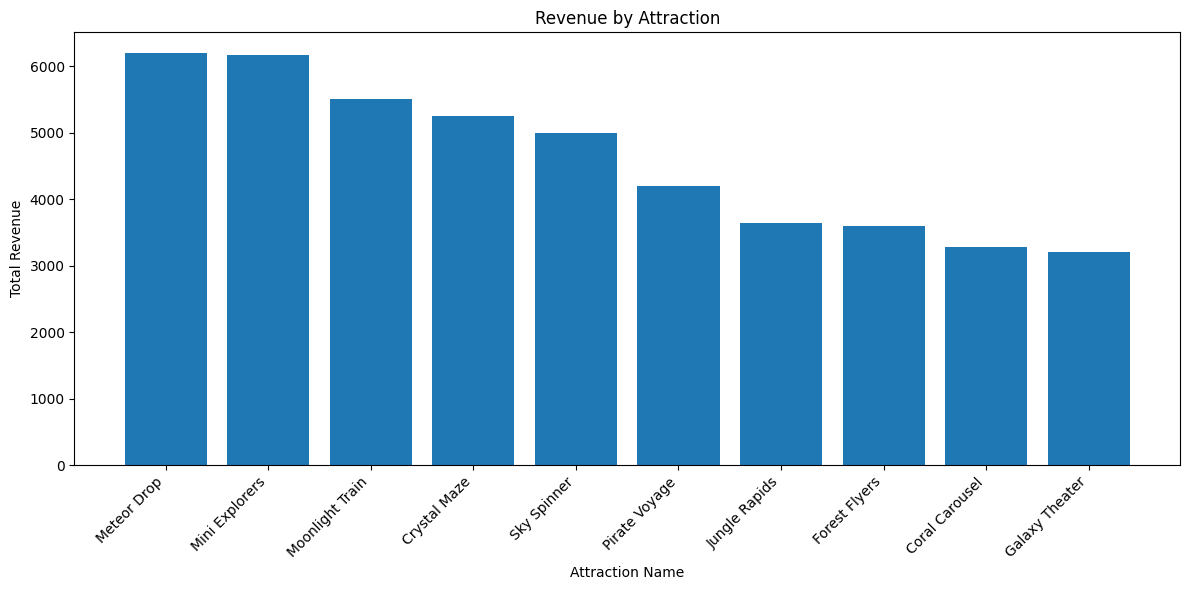

In [0]:
import matplotlib.pyplot as plt
revenue_chart = (
    gold_dashboard
    .groupBy("attraction_name")
    .agg(F.sum("total_revenue").alias("revenue"))
    .orderBy(F.desc("revenue"))
)

revenue_pd = revenue_chart.toPandas()

plt.figure(figsize=(12, 6))

plt.bar(
    revenue_pd["attraction_name"],
    revenue_pd["revenue"]
)

plt.title("Revenue by Attraction")
plt.xlabel("Attraction Name")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

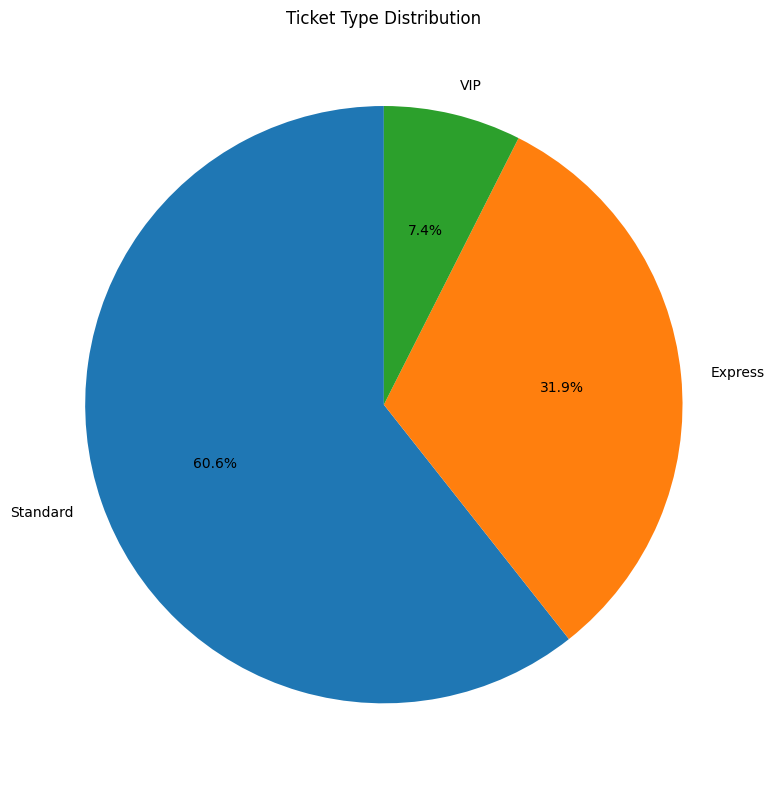

In [0]:
ticket_share = (
    spark.table(f"{PREFIX}.tp_entries_work")
    .filter(
        (F.col("status") == "Completed") &
        (F.col("ticket_price") > 0)
    )
    .groupBy("ticket_type")
    .agg(F.count("*").alias("ticket_count"))
)

ticket_pd = ticket_share.toPandas()

plt.figure(figsize=(8, 8))

plt.pie(
    ticket_pd["ticket_count"],
    labels=ticket_pd["ticket_type"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Ticket Type Distribution")
plt.tight_layout()
plt.show()

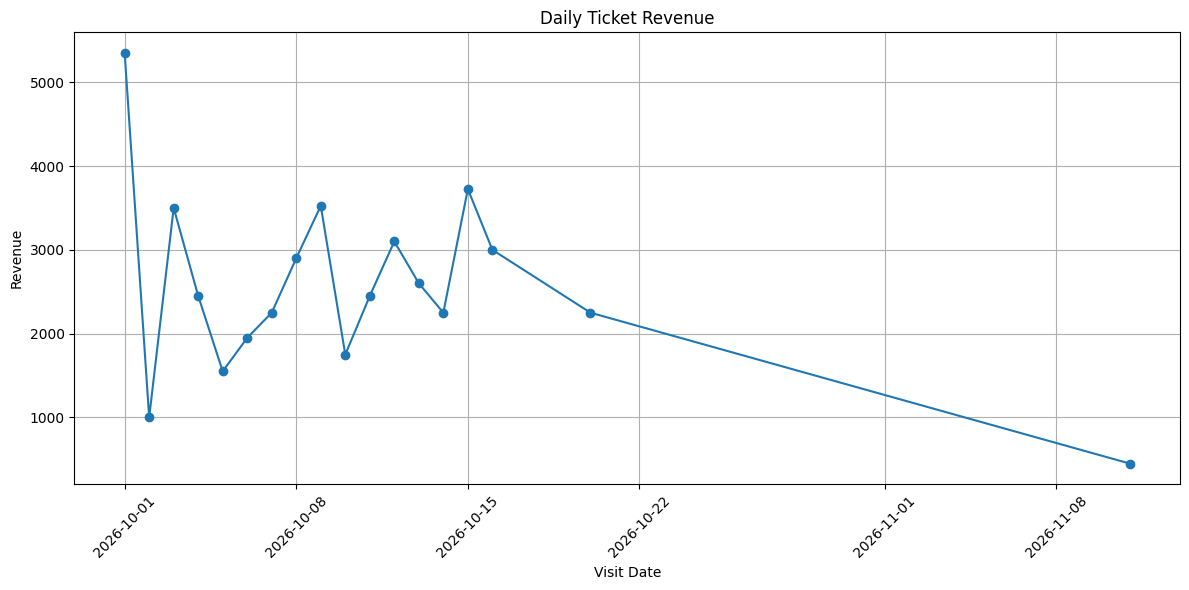

In [0]:
daily_revenue = (
    silver_df
    .withColumn("visit_date", F.to_date("visit_date"))
    .groupBy("visit_date")
    .agg(F.sum("ticket_price").alias("daily_revenue"))
    .orderBy("visit_date")
)

daily_pd = daily_revenue.toPandas()

plt.figure(figsize=(12, 6))

plt.plot(
    daily_pd["visit_date"],
    daily_pd["daily_revenue"],
    marker="o"
)

plt.title("Daily Ticket Revenue")
plt.xlabel("Visit Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

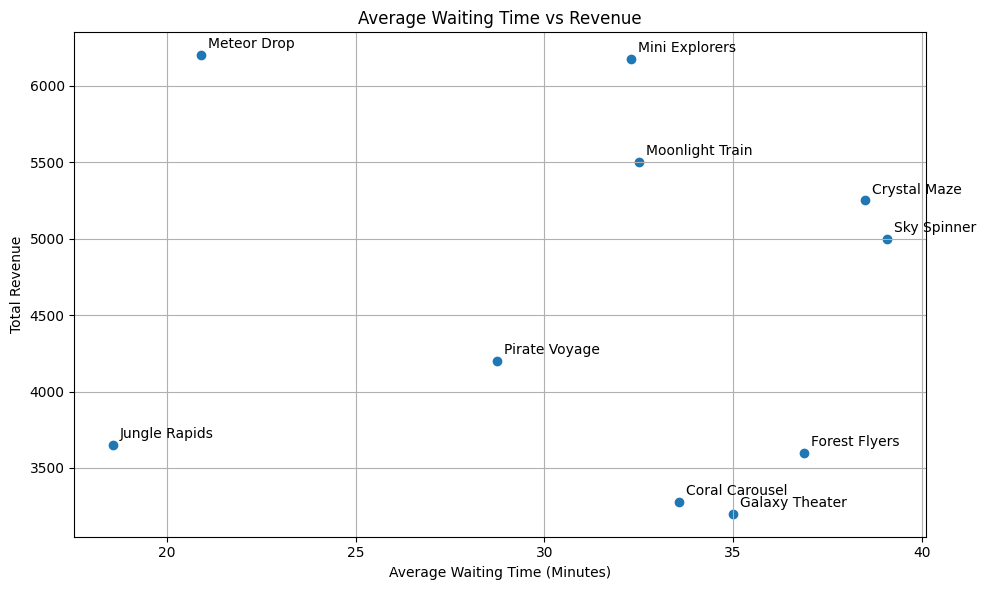

In [0]:
scatter_data = gold_dashboard.select(
    "attraction_name",
    "average_wait_minutes",
    "total_revenue"
)

scatter_pd = scatter_data.toPandas()

plt.figure(figsize=(10, 6))

plt.scatter(
    scatter_pd["average_wait_minutes"],
    scatter_pd["total_revenue"]
)

for _, row in scatter_pd.iterrows():
    plt.annotate(
        row["attraction_name"],
        (row["average_wait_minutes"], row["total_revenue"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Average Waiting Time vs Revenue")
plt.xlabel("Average Waiting Time (Minutes)")
plt.ylabel("Total Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()